# Projeto final
Atuar como Cientista de Dados para estruturar um Pipeline Preditivo completo aplicado à Indústria 4.0.
O Problema: Um parque fabril monitorado por sensores necessita prever quebras mecânicas nos equipamentos para evitar paradas na linha de produção. A variável alvo do projeto é binária: Falha = 1 (quando há uma avaria detectada) e Falha = 0 (funcionamento normal).

## Objetivo
Construir um pipeline de Machine Learning para prever `falha_maquina` em equipamentos industriais, comparando KNN e Árvore de Decisão.


# 1. Importar as bibliotecas

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Carregamento da base

In [9]:
df = pd.read_csv("manutencao_preditiva.csv")

print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")
display(df.head())


Linhas: 10000
Colunas: 14


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


## FASE 1 — Análise Exploratória (EDA)

Nesta fase serão avaliados tamanho da base, tipos de dados, estatísticas descritivas, distribuição da variável-alvo, distribuições numéricas e correlações.


In [10]:
print("=== DIMENSÕES ===")
print(df.shape)

print("\n=== TIPOS ===")
display(df.dtypes.to_frame("tipo"))

print("\n=== DESCRIBE ===")
display(df.describe())


=== DIMENSÕES ===
(10000, 14)

=== TIPOS ===


,tipo
udi,int64
id_produto,object
tipo,object
temperatura_ar_k,float64
temperatura_processo_k,float64
velocidade_rotacao_rpm,float64
torque_nm,float64
desgaste_ferramenta_min,int64
falha_maquina,int64
falha_twf,int64



=== DESCRIBE ===


,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [11]:
print("=== DISTRIBUIÇÃO DA VARIÁVEL-ALVO ===")
display(df["falha_maquina"].value_counts().rename("quantidade"))
display((df["falha_maquina"].value_counts(normalize=True) * 100).rename("percentual"))


=== DISTRIBUIÇÃO DA VARIÁVEL-ALVO ===


,quantidade
falha_maquina,
0,9661
1,339


,percentual
falha_maquina,
0,96.61
1,3.39


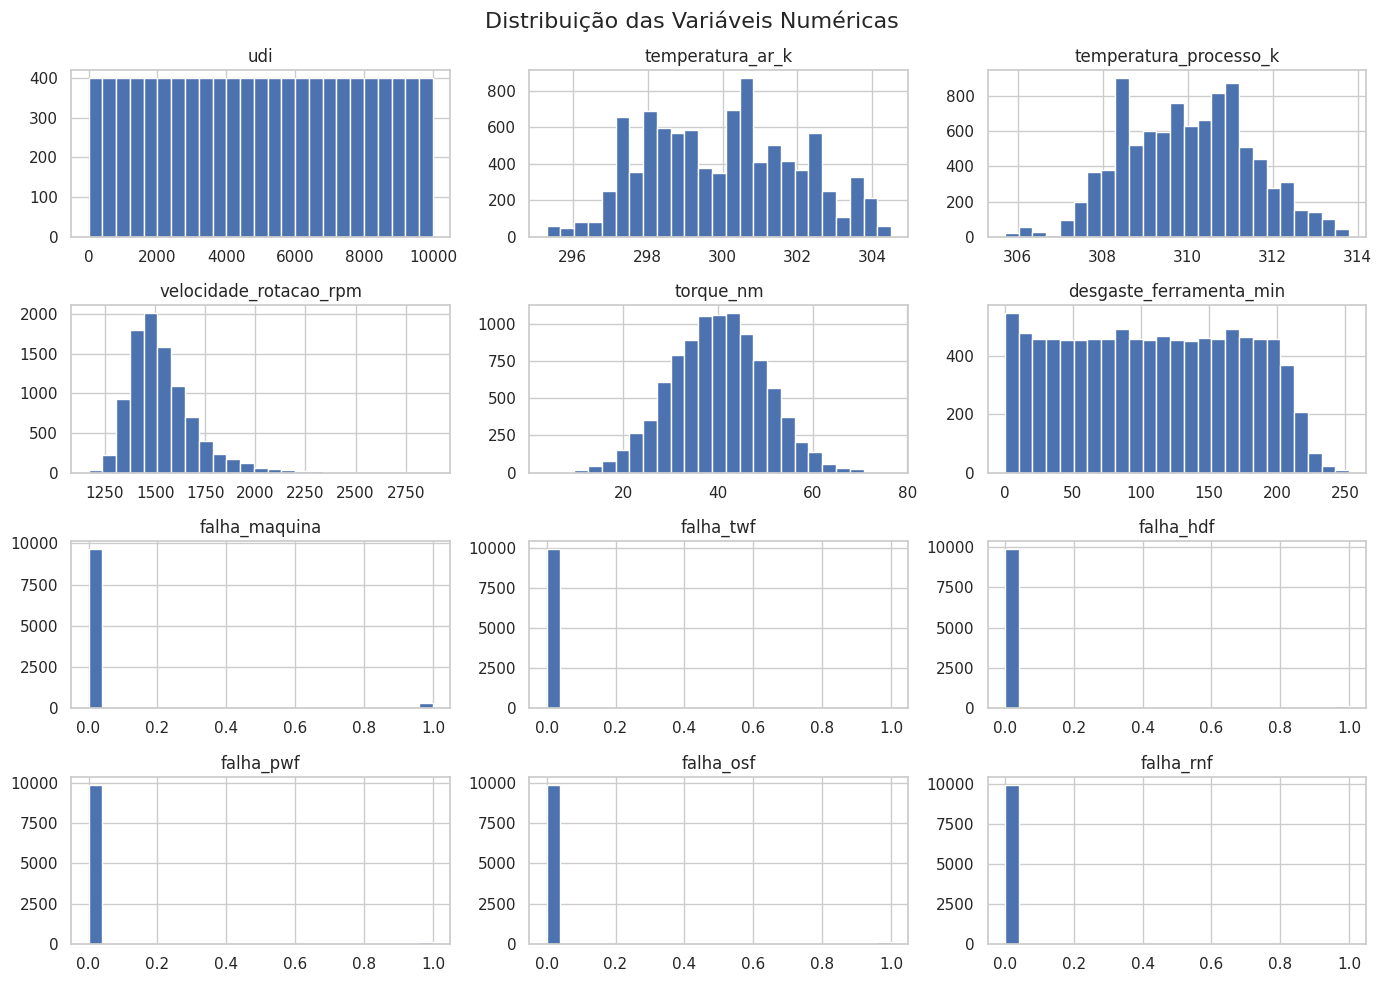

In [12]:
# Gráfico 1 — distribuições das variáveis numéricas
df.select_dtypes(include=np.number).hist(figsize=(14, 10), bins=25)
plt.suptitle("Distribuição das Variáveis Numéricas", fontsize=16)
plt.tight_layout()
plt.show()


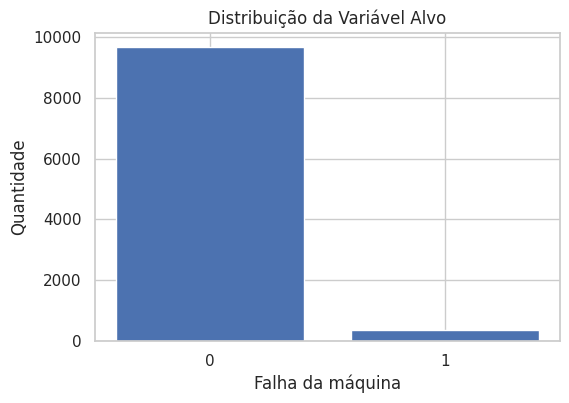

In [13]:
# Gráfico 2 — distribuição da variável-alvo
contagem_falha = df["falha_maquina"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(contagem_falha.index.astype(str), contagem_falha.values)
plt.title("Distribuição da Variável Alvo")
plt.xlabel("Falha da máquina")
plt.ylabel("Quantidade")
plt.show()


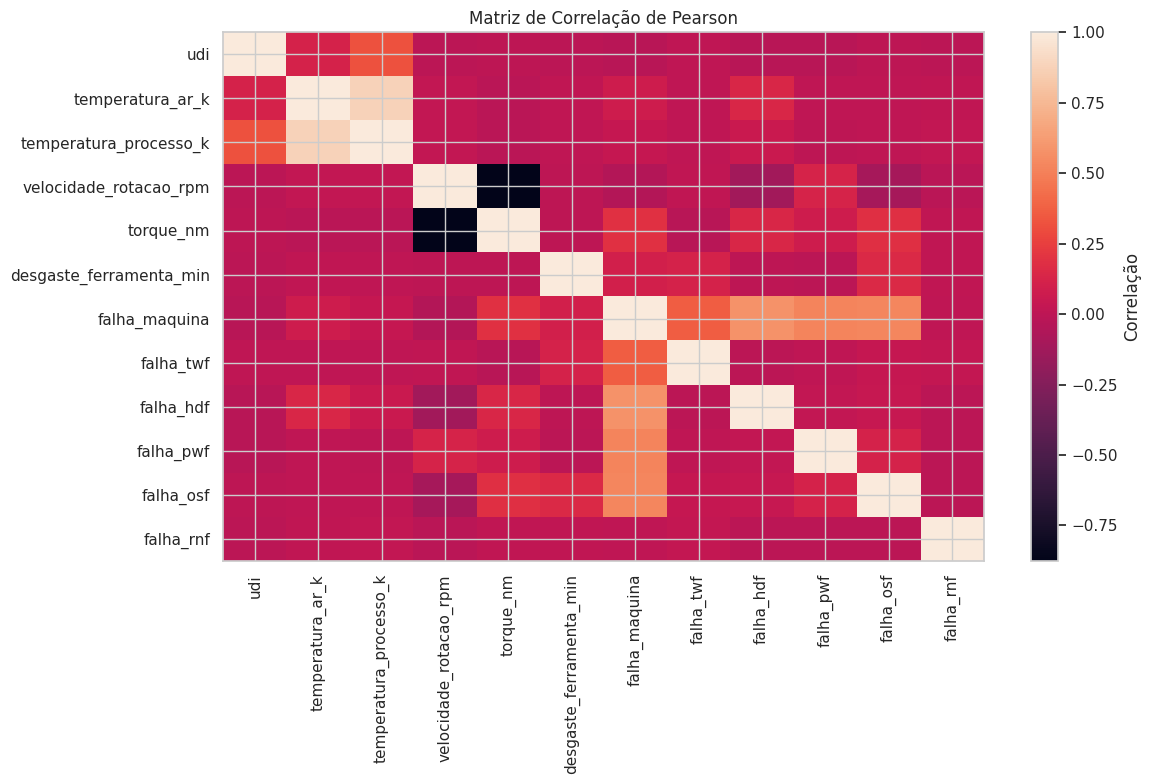

In [14]:
# Gráfico 3 — correlação de Pearson
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(12, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlação")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Matriz de Correlação de Pearson")
plt.tight_layout()
plt.show()


### Interpretação da EDA

A base possui 10.000 registros e 14 colunas. A variável `falha_maquina` é fortemente desbalanceada: a classe 0 representa aproximadamente 96,61% dos registros e a classe 1 aproximadamente 3,39%.

As variáveis operacionais apresentam distribuições diferentes; em especial, `velocidade_rotacao_rpm` apresenta assimetria positiva. A análise de correlação ajuda a identificar relações lineares, mas não deve ser usada isoladamente para decidir a relevância preditiva de uma variável.

O desbalanceamento direciona a estratégia para a aplicação de SMOTE **somente no conjunto de treinamento**, preservando o conjunto de teste com sua distribuição original.


## FASE 2 — Limpeza e Tratamento de Dados

In [15]:
print("=== DUPLICADOS ===")
print(f"Duplicados: {df.duplicated().sum()}")

print("\n=== VALORES AUSENTES ===")
display(df.isna().sum().to_frame("quantidade"))

print("\n=== PERCENTUAL DE AUSÊNCIA ===")
display((df.isna().mean() * 100).to_frame("percentual"))


=== DUPLICADOS ===
Duplicados: 0

=== VALORES AUSENTES ===


,quantidade
udi,0
id_produto,0
tipo,0
temperatura_ar_k,500
temperatura_processo_k,500
velocidade_rotacao_rpm,500
torque_nm,500
desgaste_ferramenta_min,0
falha_maquina,0
falha_twf,0



=== PERCENTUAL DE AUSÊNCIA ===


,percentual
udi,0.0
id_produto,0.0
tipo,0.0
temperatura_ar_k,5.0
temperatura_processo_k,5.0
velocidade_rotacao_rpm,5.0
torque_nm,5.0
desgaste_ferramenta_min,0.0
falha_maquina,0.0
falha_twf,0.0


In [16]:
# Remoção de duplicados
df = df.drop_duplicates().copy()
print(f"Dimensões após remoção de duplicados: {df.shape}")


Dimensões após remoção de duplicados: (10000, 14)


### Justificativa da imputação

As cinco variáveis operacionais com valores ausentes serão tratadas com **mediana**. A escolha é adequada porque a mediana é robusta à presença de valores extremos e, em particular, `velocidade_rotacao_rpm` apresenta assimetria positiva.

Para evitar vazamento de dados, a mediana será calculada **somente no conjunto de treino** e depois aplicada ao conjunto de teste.


/tmp/ipykernel_2480/3288174546.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


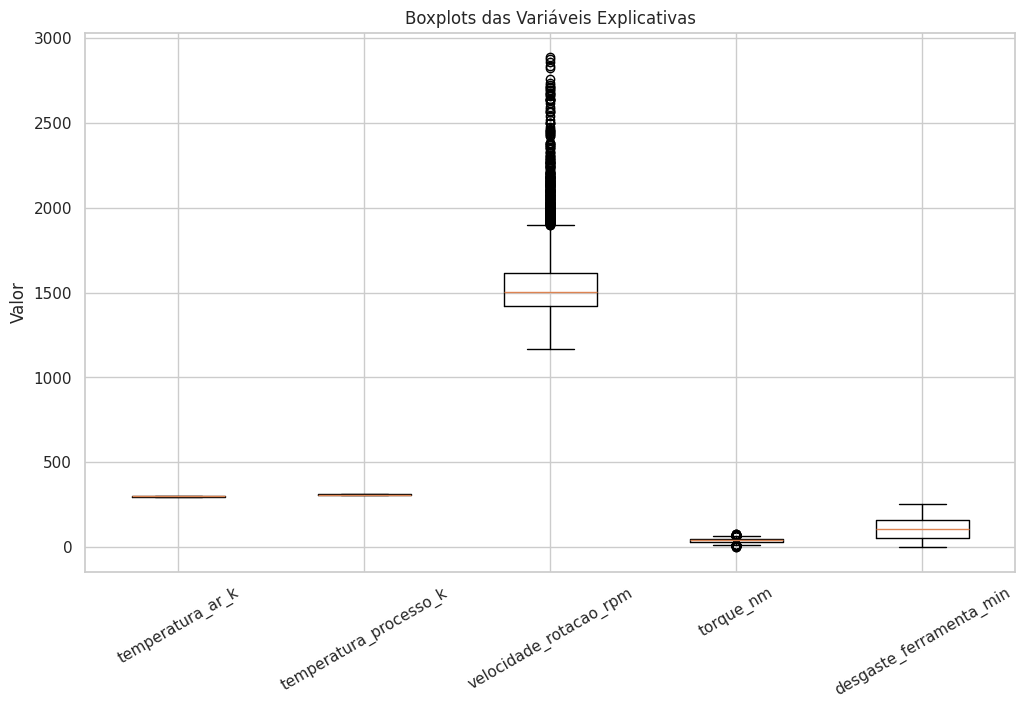

In [17]:
# Boxplots das variáveis explicativas
cont_cols_eda = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min"
]
plt.figure(figsize=(12, 7))
plt.boxplot(
    [df[c].dropna() for c in cont_cols_eda],
    labels=cont_cols_eda
)
plt.title("Boxplots das Variáveis Explicativas")
plt.xticks(rotation=30)
plt.ylabel("Valor")
plt.show()


### Análise dos boxplots

Os boxplots são utilizados para identificar observações potencialmente extremas. Valores extremos não serão removidos automaticamente: em manutenção preditiva, uma medição extrema pode representar justamente uma condição operacional importante. O tratamento será limitado à imputação dos valores ausentes, preservando as observações válidas.


## FASE 3 — Feature Engineering

Será criada a variável `potencia`, conforme a sugestão do desafio:

`potencia = velocidade_rotacao_rpm × torque_nm`

A operação será feita somente após o tratamento dos valores ausentes das duas variáveis envolvidas.


## FASE 4 — Divisão e Balanceamento dos Dados

In [18]:
target = "falha_maquina"

# Identificadores e causas específicas de falha não entram no conjunto de preditores.
excluded = [
    "udi",
    "id_produto",
    "falha_twf",
    "falha_hdf",
    "falha_pwf",
    "falha_osf",
    "falha_rnf",
    target
]

features = [c for c in df.columns if c not in excluded]

X_raw = df[features].copy()
y = df[target].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train_raw.shape)
print("Teste:", X_test_raw.shape)


Treino: (8000, 6)
Teste: (2000, 6)


In [19]:
# Imputação ajustada somente no treino
cont_cols = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min"
]

imputer = SimpleImputer(strategy="median")

X_train_num = pd.DataFrame(
    imputer.fit_transform(X_train_raw[cont_cols]),
    columns=cont_cols,
    index=X_train_raw.index
)

X_test_num = pd.DataFrame(
    imputer.transform(X_test_raw[cont_cols]),
    columns=cont_cols,
    index=X_test_raw.index
)

# Feature Engineering após imputação
X_train_num["potencia"] = (
    X_train_num["velocidade_rotacao_rpm"] *
    X_train_num["torque_nm"]
)

X_test_num["potencia"] = (
    X_test_num["velocidade_rotacao_rpm"] *
    X_test_num["torque_nm"]
)

# Codificação da variável categórica
X_train_cat = pd.get_dummies(X_train_raw[["tipo"]], dtype=int)
X_test_cat = pd.get_dummies(X_test_raw[["tipo"]], dtype=int)
X_test_cat = X_test_cat.reindex(columns=X_train_cat.columns, fill_value=0)

X_train = pd.concat([X_train_num, X_train_cat], axis=1)
X_test = pd.concat([X_test_num, X_test_cat], axis=1)

print("Variáveis finais:")
print(X_train.columns.tolist())


Variáveis finais:
['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia', 'tipo_H', 'tipo_L', 'tipo_M']


In [20]:
print("Distribuição de y no treino antes do SMOTE:")
display(y_train.value_counts())

print("Distribuição de y no teste:")
display(y_test.value_counts())

smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train,
    y_train
)

print("Distribuição de y no treino depois do SMOTE:")
display(y_train_resampled.value_counts())


Distribuição de y no treino antes do SMOTE:


,count
falha_maquina,
0,7729
1,271


Distribuição de y no teste:


,count
falha_maquina,
0,1932
1,68


Distribuição de y no treino depois do SMOTE:


,count
falha_maquina,
0,7729
1,7729


### Por que o SMOTE foi aplicado somente no treino?

O conjunto de teste representa dados que o modelo ainda não viu. Se o SMOTE fosse aplicado antes da divisão, informações derivadas de observações que deveriam permanecer no teste poderiam influenciar o treinamento. Isso produziria Data Leakage e uma avaliação artificialmente otimista.

Por isso, o teste permanece intacto e o SMOTE é aplicado exclusivamente ao treino.


## FASE 5 — Escalonamento de Variáveis

O KNN utiliza distância entre observações, portanto as variáveis contínuas precisam ser colocadas em uma escala comparável.

A Árvore de Decisão não será escalonada, pois suas decisões são baseadas em divisões/limiares dos atributos e não dependem da magnitude relativa das escalas.


In [21]:
# StandardScaler somente nas variáveis contínuas utilizadas pelo KNN
scale_cols = cont_cols + ["potencia"]

scaler = StandardScaler()

X_train_knn = X_train_resampled.copy()
X_test_knn = X_test.copy()

X_train_knn[scale_cols] = scaler.fit_transform(
    X_train_resampled[scale_cols]
)

X_test_knn[scale_cols] = scaler.transform(
    X_test[scale_cols]
)


## FASE 6 — Ajuste de Parâmetros e Combate ao Overfitting

In [22]:
# KNN: pelo menos três valores ímpares de K
k_values = [3, 5, 7, 9, 11]
resultados_knn = []

for k in k_values:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_train_knn, y_train_resampled)

    acc_train = accuracy_score(
        y_train_resampled,
        modelo.predict(X_train_knn)
    )

    acc_test = accuracy_score(
        y_test,
        modelo.predict(X_test_knn)
    )

    resultados_knn.append({
        "K": k,
        "Acurácia Treino": acc_train,
        "Acurácia Teste": acc_test,
        "Diferença Treino-Teste": acc_train - acc_test
    })

df_knn = pd.DataFrame(resultados_knn)
display(df_knn)


,K,Acurácia Treino,Acurácia Teste,Diferença Treino-Teste
0,3,0.977940,0.9265,0.051440
1,5,0.969013,0.9210,0.048013
2,7,0.963837,0.9165,0.047337
3,9,0.959309,0.9160,0.043309
4,11,0.956139,0.9145,0.041639


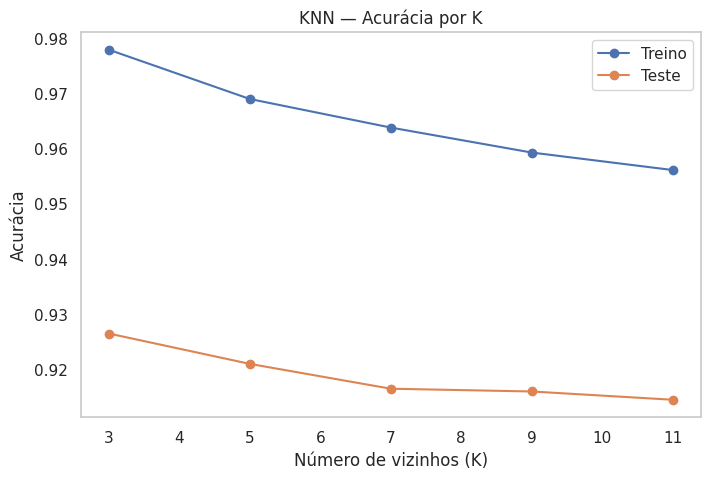

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(
    df_knn["K"],
    df_knn["Acurácia Treino"],
    marker="o",
    label="Treino"
)
plt.plot(
    df_knn["K"],
    df_knn["Acurácia Teste"],
    marker="o",
    label="Teste"
)
plt.xlabel("Número de vizinhos (K)")
plt.ylabel("Acurácia")
plt.title("KNN — Acurácia por K")
plt.legend()
plt.grid()
plt.show()


In [24]:
# Árvore de Decisão
max_depth_values = [3, 5, 7, None]
resultados_arvore = []

for profundidade in max_depth_values:
    modelo = DecisionTreeClassifier(
        max_depth=profundidade,
        random_state=42
    )
    modelo.fit(X_train_resampled, y_train_resampled)

    acc_train = accuracy_score(
        y_train_resampled,
        modelo.predict(X_train_resampled)
    )

    acc_test = accuracy_score(
        y_test,
        modelo.predict(X_test)
    )

    resultados_arvore.append({
        "max_depth": profundidade,
        "Acurácia Treino": acc_train,
        "Acurácia Teste": acc_test,
        "Diferença Treino-Teste": acc_train - acc_test
    })

df_arvore = pd.DataFrame(resultados_arvore)
display(df_arvore)


,max_depth,Acurácia Treino,Acurácia Teste,Diferença Treino-Teste
0,3.0,0.863760,0.8645,-0.000740
1,5.0,0.885496,0.8665,0.018996
2,7.0,0.912796,0.9390,-0.026204
3,NaN,0.999482,0.9485,0.050982


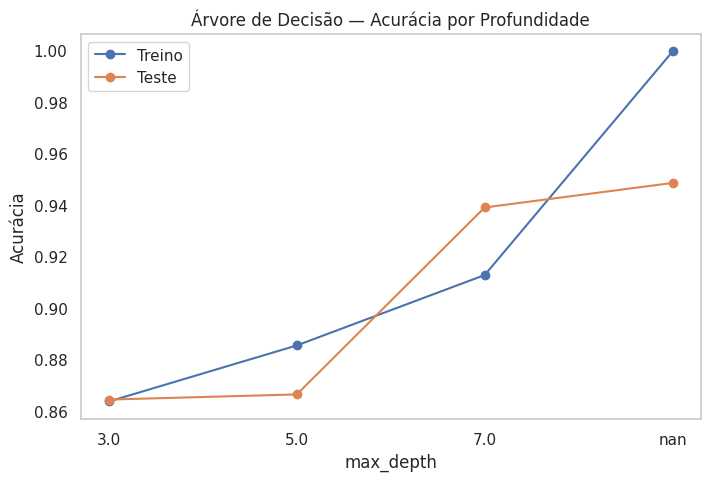

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(
    df_arvore["max_depth"].astype(str),
    df_arvore["Acurácia Treino"],
    marker="o",
    label="Treino"
)
plt.plot(
    df_arvore["max_depth"].astype(str),
    df_arvore["Acurácia Teste"],
    marker="o",
    label="Teste"
)
plt.xlabel("max_depth")
plt.ylabel("Acurácia")
plt.title("Árvore de Decisão — Acurácia por Profundidade")
plt.legend()
plt.grid()
plt.show()


### Análise do overfitting

O overfitting será identificado quando a acurácia de treino ficar muito acima da acurácia de teste.

Na árvore, `max_depth=None` tende a produzir uma árvore muito complexa e apresentou acurácia de treino praticamente perfeita. Apesar disso, neste experimento ele também apresentou a maior acurácia no conjunto de teste. Portanto, a escolha final deve considerar a regra objetiva do desafio: **maior acurácia no teste**, registrando simultaneamente o indício de maior complexidade/sobreajuste.

No KNN, valores menores de K produzem maior acurácia de treino e, neste experimento, K=3 apresentou o melhor resultado de teste entre as configurações avaliadas.


## FASE 7 — Avaliação da Acurácia e Veredito Final

In [26]:
melhor_knn = df_knn.loc[df_knn["Acurácia Teste"].idxmax()]
melhor_arvore = df_arvore.loc[df_arvore["Acurácia Teste"].idxmax()]

comparacao = pd.DataFrame({
    "Modelo": ["KNN", "Árvore de Decisão"],
    "Configuração": [
        f"K = {int(melhor_knn['K'])}",
        f"max_depth = {melhor_arvore['max_depth']}"
    ],
    "Acurácia no Teste": [
        melhor_knn["Acurácia Teste"],
        melhor_arvore["Acurácia Teste"]
    ]
})

display(comparacao)


,Modelo,Configuração,Acurácia no Teste
0,KNN,K = 3,0.9265
1,Árvore de Decisão,max_depth = nan,0.9485


In [27]:
if melhor_knn["Acurácia Teste"] > melhor_arvore["Acurácia Teste"]:
    modelo_final = "KNN"
else:
    modelo_final = "Árvore de Decisão"

print(f"Modelo recomendado: {modelo_final}")


Modelo recomendado: Árvore de Decisão


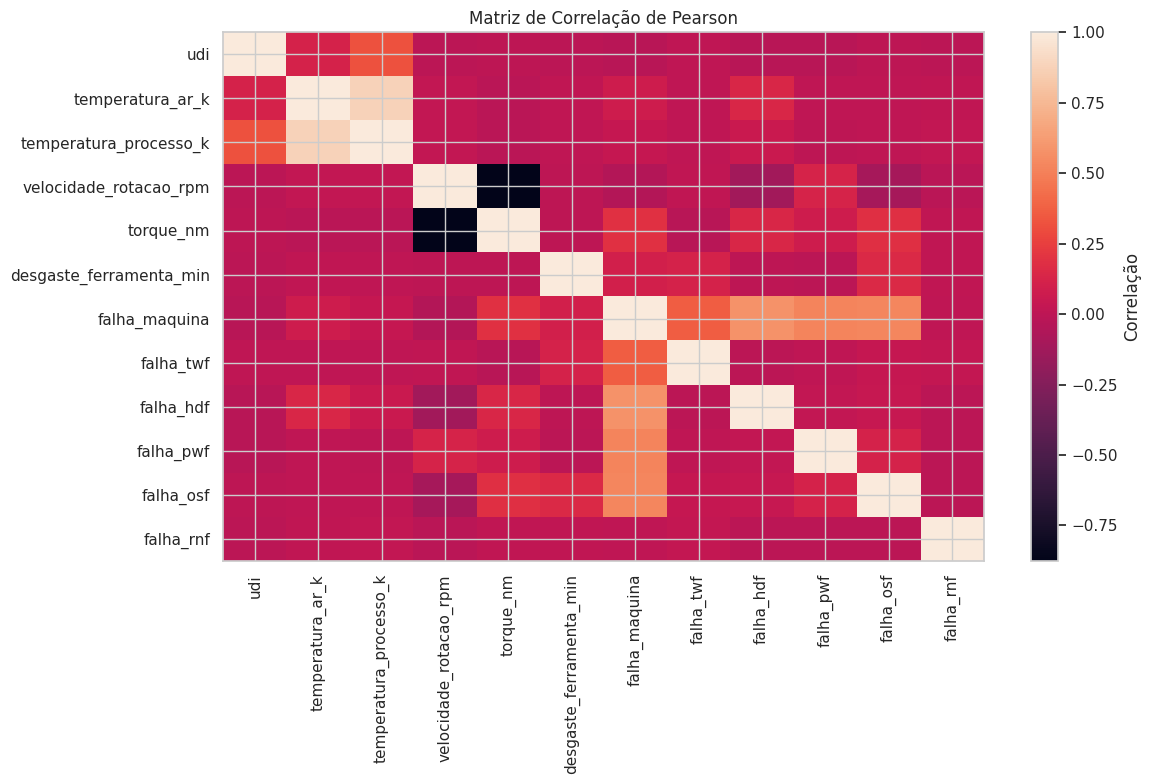

In [28]:
# Gráfico 3 — correlação de Pearson
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(12, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlação")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Matriz de Correlação de Pearson")
plt.tight_layout()
plt.show()


## Conclusão

O pipeline foi construído seguindo as etapas exigidas: EDA, tratamento de duplicados e ausentes, análise de outliers, Feature Engineering, divisão estratificada, balanceamento somente no treino, escalonamento específico para KNN, ajuste de hiperparâmetros e comparação final pela acurácia no teste.
